# Project 2

##### Authors: Ole Marius Green & Einar Aarnæs
##### Date: 2.11.26

## 3: Model problems

Required libraries:

In [1]:
import jax
import jax.numpy as jnp
import numpy as np
from matplotlib import pyplot as plt
from scipy.integrate import solve_ivp

We define our two model problems by their initial values, fields and potentials.

### 3.1: 2D charged particle

In [ ]:
@jax.jit
def B_2D(x):
    return jnp.array([0, 0, jnp.sqrt(x[0]**2+x[1]**2)])

@jax.jit
def A_2D(x):
    a_0 = -x[1]*jnp.sqrt(x[0]**2+x[1]**2)
    a_1 = x[0]*jnp.sqrt(x[0]**2+x[1]**2)
    return (1.0/3.0)*jnp.array([a_0, a_1, 0])

@jax.jit
def U_2D(x):
    return (100*np.sqrt(x[0]**2+x[1]**2))**-1

@jax.jit
def div_U_2D(x):
    divisor = (x[0]**2+x[1]**2)**(1.5)
    return -0.01*jnp.array([x[0]/divisor, x[1]/divisor, 0])

x_0_2D = np.array([0.0, 0.1, 0.1])
v_0_2D = np.array([0.09, 0.05, 0.2])

### 3.2: Tokamak magnetic field

In [3]:
@jax.jit
def B_T(x):
    x1 = x[0]
    x2 = x[1]
    x3 = x[2]
    eqlid2 = x1**2+x2**2

    b_0 = -(2*x2+x1*x3)/(2*eqlid2)
    b_1 = (2*x1-x2*x3)/(2*eqlid2)
    b_2 = (jnp.sqrt(eqlid2)-1)/(2*jnp.sqrt(eqlid2))

    return jnp.array([b_0, b_1, b_2])

@jax.jit
def A_T(x):
    x1 = x[0]
    x2 = x[1]
    x3 = x[2]
    eqlid2 = x1**2+x2**2

    a_0 = 0
    a_1 = 0.5*(x1-jnp.log(jnp.sqrt(eqlid2)+x1))
    a_2 = -0.5*(x3*jnp.atan(x2/x1) + jnp.log(eqlid2))

    return jnp.array([a_0, a_1, a_2])

def U_T(x):
    return 0.0

@jax.jit
def div_U_T(x):
    return jnp.array([0.0, 0.0, 0.0])

x_0_T = np.array([1.2, 0., 0.0])
v_0_T = np.array([0, 4.816e-4, -2.059e-3])

## 4: Implementation of methods

### 4.1: Boris method

In [4]:
@jax.jit(static_argnames=["B", "div_U"])
def _boris_jit_loop(x_init, v_init, v_minus_half_0, h, B, div_U):
    n_steps = x_init.shape[0] - 1

    def step_fn(i, state):

        #### OBS: PASSING X IS OBSOLETE
        x_vals, v_vals, x, v_minus_half = state

        k = 0.5*h*B(x)
        s = 2*k/(1 + jnp.dot(k, k))
        v_minus = v_minus_half - 0.5*h*div_U(x)
        v_marked = v_minus + jnp.cross(v_minus, k)
        v_plus = v_minus + jnp.cross(v_marked, s)
        v_plus_half = v_plus - 0.5*h*div_U(x)

        x_next = x + h * v_plus_half

        v_centered = 0.5 * (v_minus_half + v_plus_half)

        # Functional history array updates
        x_updated = x_vals.at[i].set(x_next)
        v_updated = v_vals.at[i].set(v_centered)

        return (x_updated, v_updated, x_next, v_plus_half)

    initial_state = (x_init, v_init, x_init[0], v_minus_half_0)

    x_final, v_final, _, _ = jax.lax.fori_loop(1, n_steps + 1, step_fn, initial_state)

    return x_final, v_final



def Boris_Method(x0, v0, t_stop, h, B, div_U):
    n_steps = int(np.ceil(t_stop/h))
    t0 = 0.0
    t_vals = t0 + np.arange(n_steps+1) * h

    #Startup to get v_(-1/2) using SciPy solve_ivp
    def rhs(t_val, u):
        x_, v_ = u[:3], u[3:]
        return np.concatenate((v_, np.cross(v_, B(x_)) - div_U(x_)))

    sol0 = solve_ivp(rhs, (t0, t0 - h), np.concatenate((x0, v0)), t_eval=[t0 - 0.5*h])
    v_minus_half_0 = jnp.asarray(sol0.y[3:, 0])

    x_init = jnp.zeros((n_steps + 1, 3)).at[0].set(x0)
    v_init = jnp.zeros((n_steps + 1, 3)).at[0].set(v0)

    x_vals, v_vals = _boris_jit_loop(x_init, v_init, v_minus_half_0, h, B, div_U)

    #Setting v[0] = v0 to keep initial velocity exact
    v_vals = v_vals.at[0].set(v0)

    return t_vals, np.asarray(x_vals), np.asarray(v_vals)

### 4.2: Classical Runge-Kutta 4 on the extended system

In [5]:
@jax.jit(static_argnames=["B", "div_U"])
def _rk4_jit_loop(x_init, v_init, h, B, div_U):
    n_steps = x_init.shape[0] - 1

    def f(x_curr, v_curr):
        return jnp.cross(v_curr, B(x_curr)) - div_U(x_curr)

    def step_fn(i, state):
        x_arr, v_arr, x, v = state

        k1v = h*f(x, v)
        k1x = h*v
        k2v = h*f(x + 0.5*k1x, v + 0.5*k1v)
        k2x = h*(v + 0.5*k1v)
        k3v = h*f(x + 0.5*k2x, v + 0.5*k2v)
        k3x = h*(v + 0.5*k2v)
        k4v = h*f(x + k3x, v + k3v)
        k4x = h*(v + k3v)


        x_next = x + (1.0 / 6.0) * (k1x + 2.0 * k2x + 2.0 * k3x + k4x)
        v_next = v + (1.0 / 6.0) * (k1v + 2.0 * k2v + 2.0 * k3v + k4v)


        x_updated = x_arr.at[i].set(x_next)
        v_updated = v_arr.at[i].set(v_next)

        return (x_updated, v_updated, x_next, v_next)

    # Execute JIT-compiled loop from step 1 to n_steps
    initial_state = (x_init, v_init, x_init[0], v_init[0])
    x_final, v_final, _, _ = jax.lax.fori_loop(1, n_steps + 1, step_fn, initial_state)

    return x_final, v_final


def RK_4(x0, v0, t_stop, h, B, div_U):
    n_steps = int(np.ceil(t_stop / h))
    t0 = 0.0

    t_vals = t0 + np.arange(n_steps + 1) * h

    x_init = jnp.zeros((n_steps + 1, 3)).at[0].set(x0)
    v_init = jnp.zeros((n_steps + 1, 3)).at[0].set(v0)

    # Run compiled loop
    x_vals, v_vals = _rk4_jit_loop(x_init, v_init, h, B, div_U)

    return t_vals, np.asarray(x_vals), np.asarray(v_vals)


### 4.3: Fourth-order symmetric multistep method

In [6]:

@jax.jit(static_argnames=["A", "div_U", "A_jac"])
def _multistep_jit_loop(x_init, v_init, h, alpha, alpha_4, beta, A, div_U, A_jac):
    n_steps = x_init.shape[0] - 1
    
    def compute_F(k, x_arr):
        v_k = (1.0 / (12.0 * h)) * (x_arr[k - 2]- 8.0 * x_arr[k - 1]+ 8.0 * x_arr[k + 1]- x_arr[k + 2])
        A_delta_k = (1.0 / (12.0 * h)) * (A(x_arr[k - 2])- 8.0 * A(x_arr[k - 1])+ 8.0 * A(x_arr[k + 1])- A(x_arr[k + 2]))
        J_k = A_jac(x_arr[k])
        grad_U_k = div_U(x_arr[k])
        return J_k.T @ v_k - A_delta_k - grad_U_k

    F_3_init = compute_F(3, x_init)
    F_4_init = compute_F(4, x_init)

    
    def step_fn(j, state):
        x_arr, F_prev1, F_prev2 = state
        F_next = compute_F(j + 1, x_arr)

        force_term = (h**2) * (beta[0] * F_prev1 + beta[1] * F_prev2 + beta[2] * F_next)

        history_slice = jax.lax.dynamic_slice_in_dim(x_arr, start_index=j - 4, slice_size=8, axis=0)
        history_term = jnp.einsum("k,kd->d", alpha, history_slice)
        
        x_new = (1.0 / alpha_4) * (force_term - history_term)
        x_updated = x_arr.at[j + 4].set(x_new)

        return (x_updated, F_prev2, F_next)

   
    initial_state = (x_init, F_3_init, F_4_init)
    x_final, _, _ = jax.lax.fori_loop(4, n_steps - 3, step_fn, initial_state)


    v_interior = (1.0 / (12.0 * h)) * (x_final[0:-4] - 8.0 * x_final[1:-3] + 8.0 * x_final[3:-1] - x_final[4:])
    v_final = v_init.at[2:-2].set(v_interior)

    return x_final, v_final



def multistep(x0, v0, t_stop, h, A, div_U):

    A_jacobian = jax.jacobian(A)
    A_jac_jit = jax.jit(A_jacobian)

    #Defining constants
    a1, a2, a3 = -0.7, 0.1, 0.9
    sum_a = a1 + a2 + a3
    sum_prod2 = a1 * a2 + a1 * a3 + a2 * a3
    prod3 = a1 * a2 * a3
        
    beta_0 = (1.0 / 3.0) * (20 * prod3 - 4 * sum_prod2 - 28 * sum_a - 52)
    beta_1 = (1.0 / 3.0) * (2 * prod3 + 14 * sum_prod2 + 26 * sum_a + 38)

    beta = jnp.array([beta_1, beta_0, beta_1])

    alpha = jnp.array([1.0, -7/5, 9/25, 22/125, -34/125, 22/125, 9/25, -7/5, 1.0])

    alpha_4 = alpha[-1]
    alpha = alpha[:-1]

    n_steps = int(np.ceil(t_stop / h))
    t0 = 0.0
    t = t0 + np.arange(n_steps + 1) * h

    x_init = jnp.zeros((n_steps + 1, 3)).at[0].set(x0)
    v_init = jnp.zeros((n_steps + 1, 3)).at[0].set(v0)

    #Generating the first 8 values by solve_ivp RK45 with rtol=1e-10, atol=1e-12
    def rhs(t_, u):
        x_, v_ = u[:3], u[3:]
        J = np.asarray(A_jacobian(x_))
        B = np.array([J[2, 1] - J[1, 2], J[0, 2] - J[2, 0], J[1, 0] - J[0, 1]])
        return np.concatenate([v_, np.cross(v_, B) - div_U(x_)])

    t_start = t[1:8]
    sol0 = solve_ivp(rhs, (t0, t0+9*h), np.concatenate((x0, v0)), t_eval = t_start, rtol=1e-10, atol=1e-12)

    x_init = x_init.at[1:8].set(sol0.y[:3, :].T)
    v_init = v_init.at[1:8].set(sol0.y[3:, :].T)

    
    # Run JIT-compiled loop
    x_vals, v_vals = _multistep_jit_loop(x_init, v_init, h, alpha, alpha_4, beta, A, div_U, A_jac_jit)

    return t, np.asarray(x_vals), np.asarray(v_vals)

    

## 5: Experiments and deliverables

### A. Plotting trajectories and error over long time

In [7]:
# Defining the end time T and step size h

#Change to 1e5
T = 1e5
h = 0.1

### 2D charged particle

In [8]:
t_2D_boris, x_2D_boris, v_2D_boris = Boris_Method(x_0_2D, v_0_2D, T, h, B_2D, div_U_2D)
t_2D_RK, x_2D_RK, v_2D_RK = RK_4(x_0_2D, v_0_2D, T, h, B_2D, div_U_2D)
t_2D_multi, x_2D_multi, v_2D_multi = multistep(x_0_2D, v_0_2D, T, h, A_2D, div_U_2D)

##### 1. Trajectories

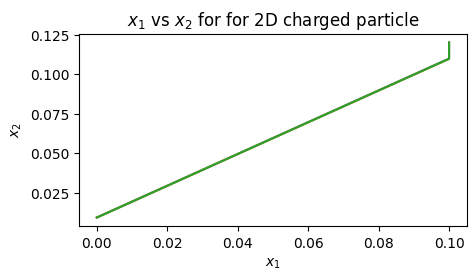

Boris: (3,)
RK4: (3,)
Multistep: (3,)
Boris: (1000001,)
RK4: (1000001,)
Multistep: (1000001,)


In [25]:
fig, axs = plt.subplots(nrows = 1, ncols = 1, figsize = (5, 2.5))
axs.plot(x_2D_boris[0, :], x_2D_boris[1, :], label = "Boris method")
axs.plot(x_2D_RK[0, :], x_2D_RK[1, :], label = "RK4")
axs.plot(x_2D_multi[0, :], x_2D_multi[1, :], label = "Multistep")

axs.set(xlabel = r"$x_1$", ylabel = r"$x_2$", title = r"$x_1$ vs $x_2$ for for 2D charged particle")

plt.show()

print("Boris:", x_2D_boris[0, :].shape)
print("RK4:", x_2D_RK[0, :].shape)
print("Multistep:",x_2D_multi[0, :].shape)
print("Boris:", x_2D_boris[:, 0].shape)
print("RK4:", x_2D_RK[:, 0].shape)
print("Multistep:",x_2D_multi[:, 0].shape)

##### 2. Error

##### 3. Change in energy

### Tolamak magnetic field

In [10]:
t_T_boris, x_T_boris, v_T_boris = Boris_Method(x_0_T, v_0_T, T, h, B_T, div_U_T)
t_T_RK, x_T_RK, v_T_RK = RK_4(x_0_T, v_0_T, T, h, B_T, div_U_T)
t_T_multi, x_T_multi, v_T_multi = multistep(x_0_T, v_0_T, T, h, A_T, div_U_T)

##### 1. Trajectories

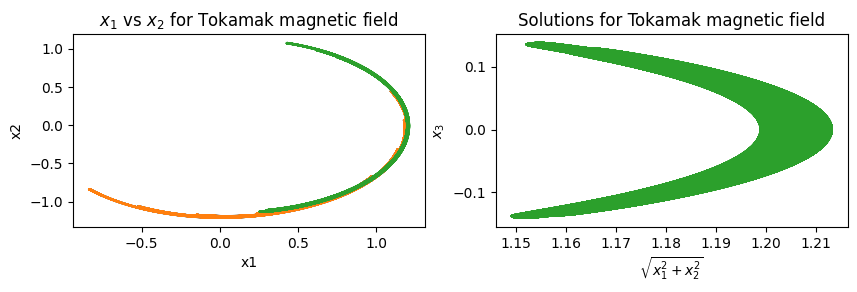

Boris: (3,)
RK4: (3,)
Multistep: (3,)
Boris: (1000001,)
RK4: (1000001,)
Multistep: (1000001,)


In [21]:
def R(x):
    return np.sqrt(x[:, 0]**2 + x[:, 1]**2)

fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 2.5))
axs[0].plot(x_T_boris[:, 0], x_T_boris[:, 1], label = "Boris method")
axs[0].plot(x_T_RK[:, 0], x_T_RK[:, 1], label = "RK4")
axs[0].plot(x_T_multi[:, 0], x_T_multi[:, 1], label = "Multistep")

axs[1].plot(R(x_T_boris) , x_T_boris[:, 2], label = "Boris method")
axs[1].plot(R(x_T_RK), x_T_RK[:, 2], label = "RK4")
axs[1].plot(R(x_T_multi), x_T_multi[:, 2], label = "Multistep")

axs[0].set(xlabel = "x1", ylabel = "x2", title = r"$x_1$ vs $x_2$ for Tokamak magnetic field")
axs[1].set(xlabel = r"$\sqrt{x_1^2+x_2^2}$", ylabel = "$x_3$", title = "Solutions for Tokamak magnetic field")

plt.show()

print("Boris:", x_T_boris[0, :].shape)
print("RK4:", x_T_RK[0, :].shape)
print("Multistep:", x_T_multi[0, :].shape)
print("Boris:", x_T_boris[:, 0].shape)
print("RK4:", x_T_RK[:, 0].shape)
print("Multistep:", x_T_multi[:, 0].shape)

##### 2. Error

##### 3. Change in energy

### B. Order verification and work precision diagrams

### C. Exploratory exercise 